# Práctica — Selección de variables con redes neuronales
## Consigna 1: regresión temporal del consumo de electrodomésticos

**Alumno:** Juan Pablo Pillack  
**Materia:** Inteligencia Artificial · Semana 6, clase 6 · Ingeniería y selección de características
**Dataset:** *Appliances Energy Prediction* (UCI ML Repository, id 374, licencia CC BY 4.0)

**Objetivo.** Explorar las variables ambientales y temporales, seleccionar un subconjunto informativo y
comparar una RNA entrenada con **todas** las variables contra **la misma arquitectura** entrenada con el
subconjunto seleccionado, para predecir `Appliances` (Wh cada 10 minutos).

### Reglas que respeta todo el notebook

| Regla de la consigna | Cómo se cumple acá |
|---|---|
| Ordenar por `date` y no usar la fecha como texto | Se ordena cronológicamente y `date` se transforma en `hour_sin`, `hour_cos` y `day_of_week`; la columna `date` se descarta antes de entrenar. |
| Partición que respete el orden temporal | 70 % / 15 % / 15 % cronológico (sin mezclar), igual que el código inicial. |
| Selección de variables solo con entrenamiento | Toda la exploración, los rankings (correlación, información mutua, Lasso, permutación) y la detección de redundancias se calculan **solo sobre `X_train`**. Validación se usa únicamente para comparar candidatos ya construidos. |
| La prueba se evalúa una sola vez | El conjunto de prueba se toca en una única celda, al final, con la configuración ya congelada. |
| Cambiar solo el conjunto de variables | Una única función `crear_rna()` define arquitectura, semilla y preprocesamiento; todos los experimentos la reutilizan. |

## 1. Preparación del entorno

In [1]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from ucimlrepo import fetch_ucirepo

# El MLP del código inicial (max_iter=800) a veces llega al tope de iteraciones
# sin cumplir la tolerancia. Es esperable y no cambia la comparación, así que se
# silencia el aviso para que la salida sea legible.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.precision", 3)
SEMILLA = 42

## 2. Descarga, orden temporal y atributos de fecha (actividades 1 y 2)

Se parte del código inicial de la cátedra. **Única corrección:** en la versión actual de `ucimlrepo`
la columna `date` llega sin espacio entre fecha y hora (`"2016-01-1117:00:00"`), y
`pd.to_datetime(df["date"])` falla con `DateParseError`. Se pasa el formato explícito; el resultado es
el mismo instante temporal que en el CSV original de UCI.

In [3]:
energy = fetch_ucirepo(id=374)
X_raw = energy.data.features.copy()
y_raw = energy.data.targets.squeeze().astype(float)

df = X_raw.copy()
df["Appliances"] = y_raw.to_numpy()
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d%H:%M:%S")  # corrección de formato
df = df.sort_values("date").reset_index(drop=True)

# Atributos temporales básicos (codificación cíclica de la hora: 23 h y 0 h quedan cerca)
df["hour_sin"] = np.sin(2 * np.pi * df["date"].dt.hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["date"].dt.hour / 24)
df["day_of_week"] = df["date"].dt.dayofweek

fechas = df["date"].copy()          # se guarda solo para graficar y para describir las particiones
y = df.pop("Appliances")
X = df.drop(columns="date").astype(float)
print(X.shape)
print("Intervalo:", fechas.min(), "→", fechas.max())
print("Paso entre registros:", fechas.diff().dropna().unique())
display(X.head())

(19735, 30)
Intervalo: 2016-01-11 17:00:00 → 2016-05-27 18:00:00
Paso entre registros: <TimedeltaArray>
['0 days 00:10:00']
Length: 1, dtype: timedelta64[ns]


,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,hour_sin,hour_cos,day_of_week
0,30.0,19.89,47.597,19.2,44.790,19.79,44.730,19.000,45.567,17.167,...,733.5,92.0,7.000,63.000,5.3,13.275,13.275,-0.966,-0.259,0.0
1,30.0,19.89,46.693,19.2,44.722,19.79,44.790,19.000,45.992,17.167,...,733.6,92.0,6.667,59.167,5.2,18.606,18.606,-0.966,-0.259,0.0
2,30.0,19.89,46.300,19.2,44.627,19.79,44.933,18.927,45.890,17.167,...,733.7,92.0,6.333,55.333,5.1,28.643,28.643,-0.966,-0.259,0.0
3,40.0,19.89,46.067,19.2,44.590,19.79,45.000,18.890,45.723,17.167,...,733.8,92.0,6.000,51.500,5.0,45.410,45.410,-0.966,-0.259,0.0
4,40.0,19.89,46.333,19.2,44.530,19.79,45.000,18.890,45.530,17.200,...,733.9,92.0,5.667,47.667,4.9,10.084,10.084,-0.966,-0.259,0.0


### Descripción de las variables

Según la documentación del dataset (Candanedo et al., 2017):

| Grupo | Variables | Significado |
|---|---|---|
| Objetivo | `Appliances` | Energía consumida por electrodomésticos en los 10 minutos (Wh). |
| Iluminación | `lights` | Energía de las luminarias de la casa (Wh). |
| Sensores interiores | `T1`–`T9`, `RH_1`–`RH_9` | Temperatura (°C) y humedad relativa (%) por ambiente: 1 cocina, 2 living, 3 lavadero, 4 oficina, 5 baño, 6 exterior norte del edificio, 7 cuarto de planchado, 8 dormitorio adolescente, 9 dormitorio de padres. |
| Estación meteorológica | `T_out`, `Press_mm_hg`, `RH_out`, `Windspeed`, `Visibility`, `Tdewpoint` | Clima exterior (aeropuerto de Chièvres, interpolado a 10 min). |
| Control | `rv1`, `rv2` | Variables **aleatorias** agregadas por los autores para comprobar que los métodos de selección no elijan ruido. |
| Derivadas de `date` | `hour_sin`, `hour_cos`, `day_of_week` | Hora del día (codificación cíclica) y día de la semana (0 = lunes). |

In [4]:
display(pd.concat([y.rename("Appliances"), X], axis=1).describe().T)
print("Valores faltantes totales:", int(X.isna().sum().sum() + y.isna().sum()))

,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,9.769e+01,102.525,10.000,50.000,6.000e+01,100.000,1080.000
lights,19735.0,3.802e+00,7.936,0.000,0.000,0.000e+00,0.000,70.000
T1,19735.0,2.169e+01,1.606,16.790,20.760,2.160e+01,22.600,26.260
RH_1,19735.0,4.026e+01,3.979,27.023,37.333,3.966e+01,43.067,63.360
T2,19735.0,2.034e+01,2.193,16.100,18.790,2.000e+01,21.500,29.857
RH_2,19735.0,4.042e+01,4.070,20.463,37.900,4.050e+01,43.260,56.027
T3,19735.0,2.227e+01,2.006,17.200,20.790,2.210e+01,23.290,29.236
RH_3,19735.0,3.924e+01,3.255,28.767,36.900,3.853e+01,41.760,50.163
T4,19735.0,2.086e+01,2.043,15.100,19.530,2.067e+01,22.100,26.200
RH_4,19735.0,3.903e+01,4.341,27.660,35.530,3.840e+01,42.157,51.090


Valores faltantes totales: 0


## 3. Partición cronológica (actividad 6)

Se hace **antes** de explorar, para que todo el análisis de relevancia y redundancia mire solo el
entrenamiento. Se mantiene la partición del código inicial: 70 % / 15 % / 15 % en orden temporal.

In [5]:
n = len(X)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

X_train, y_train = X.iloc[:fin_train], y.iloc[:fin_train]
X_val, y_val = X.iloc[fin_train:fin_val], y.iloc[fin_train:fin_val]
X_test, y_test = X.iloc[fin_val:], y.iloc[fin_val:]

resumen = pd.DataFrame({
    "desde": [fechas.iloc[0], fechas.iloc[fin_train], fechas.iloc[fin_val]],
    "hasta": [fechas.iloc[fin_train - 1], fechas.iloc[fin_val - 1], fechas.iloc[-1]],
    "filas": [len(X_train), len(X_val), len(X_test)],
    "media Appliances": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "validación", "prueba"])
display(resumen)

,desde,hasta,filas,media Appliances
train,2016-01-11 17:00:00,2016-04-16 15:10:00,13814,98.775
validación,2016-04-16 15:20:00,2016-05-07 04:30:00,2960,93.422
prueba,2016-05-07 04:40:00,2016-05-27 18:00:00,2961,96.927


## 4. Exploración (solo entrenamiento) — actividad 3

### 4.1 Objetivo

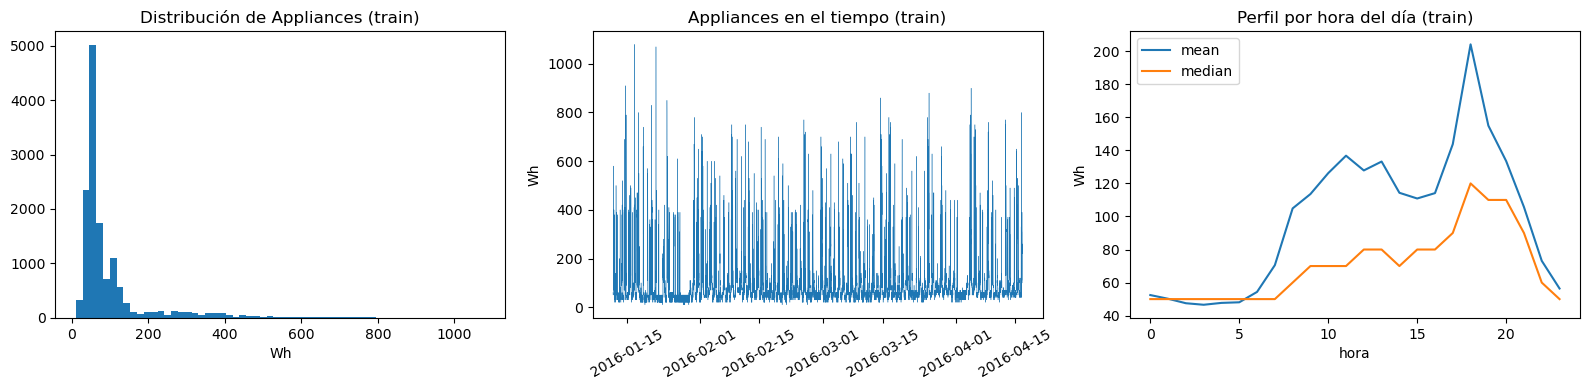

Asimetría: 3.25 · mediana 60 Wh · media 98.8 Wh · p95 340 Wh


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(y_train, bins=60)
ax[0].set(title="Distribución de Appliances (train)", xlabel="Wh")
ax[1].plot(fechas.iloc[:fin_train], y_train, lw=0.3)
ax[1].set(title="Appliances en el tiempo (train)", ylabel="Wh")
ax[1].tick_params(axis="x", rotation=30)
hora_train = fechas.iloc[:fin_train].dt.hour
y_train.groupby(hora_train.to_numpy()).agg(["mean", "median"]).plot(ax=ax[2])
ax[2].set(title="Perfil por hora del día (train)", xlabel="hora", ylabel="Wh")
plt.tight_layout()
plt.show()
print(f"Asimetría: {y_train.skew():.2f} · mediana {y_train.median():.0f} Wh · media {y_train.mean():.1f} Wh · p95 {y_train.quantile(.95):.0f} Wh")

El objetivo es muy asimétrico (la mayoría de los registros están entre 50 y 100 Wh, con picos de hasta
~1000 Wh) y tiene un perfil diario marcado: casi plano de madrugada y con picos al mediodía y a la
tarde-noche. Ya esto anticipa que la **hora** va a ser una de las variables más informativas.

### 4.2 Asociación de cada variable con `Appliances`

Se usan dos medidas complementarias: **Spearman** (monótona, robusta a la asimetría del objetivo) e
**información mutua** (capta relaciones no lineales, como la de la hora).

,pearson,spearman,info_mutua,|spearman|
hour_sin,-0.250,-0.431,0.169,0.431
lights,0.226,0.354,0.081,0.354
T2,0.150,0.325,0.108,0.325
hour_cos,-0.226,-0.297,0.109,0.297
T1,0.084,0.265,0.088,0.265
T8,0.072,0.258,0.115,0.258
T4,0.077,0.240,0.116,0.240
T3,0.121,0.239,0.120,0.239
RH_8,-0.116,-0.235,0.092,0.235
RH_out,-0.147,-0.220,0.038,0.220


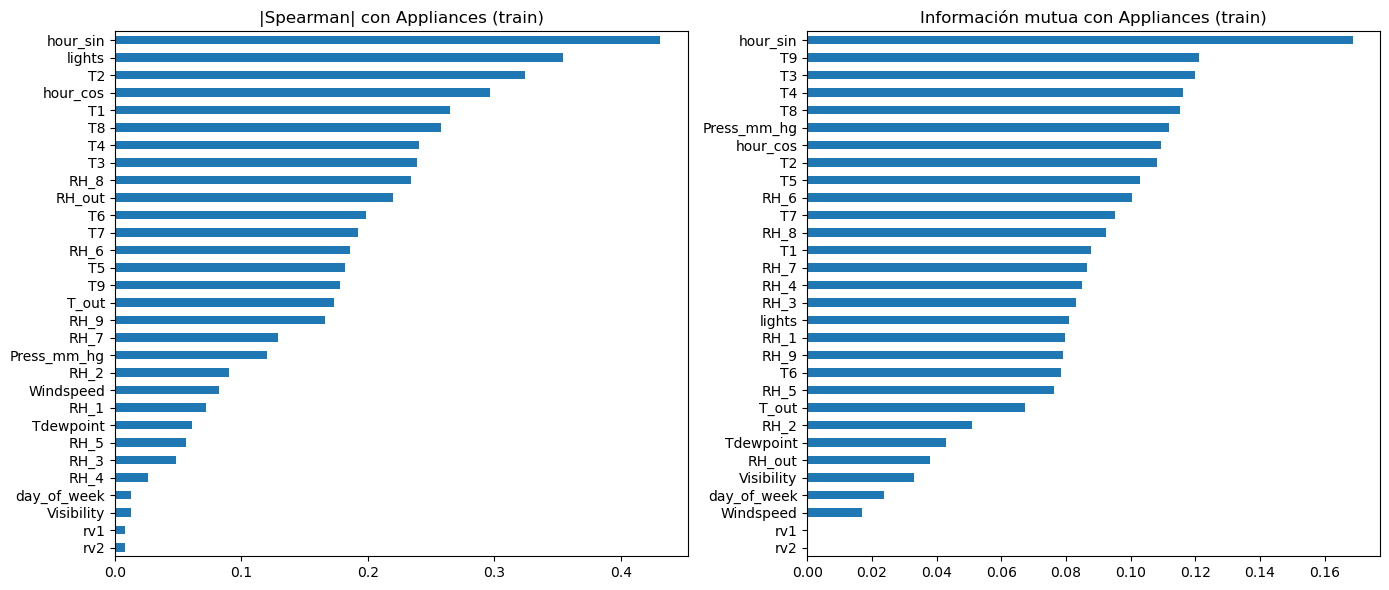

In [7]:
asociacion = pd.DataFrame({
    "pearson": X_train.corrwith(y_train),
    "spearman": X_train.corrwith(y_train, method="spearman"),
    "info_mutua": mutual_info_regression(X_train, y_train, random_state=SEMILLA),
})
asociacion["|spearman|"] = asociacion["spearman"].abs()
asociacion = asociacion.sort_values("|spearman|", ascending=False)
display(asociacion)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
asociacion["|spearman|"].plot.barh(ax=ax[0]); ax[0].invert_yaxis(); ax[0].set_title("|Spearman| con Appliances (train)")
asociacion["info_mutua"].sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Información mutua con Appliances (train)")
plt.tight_layout(); plt.show()

### 4.3 Redundancia entre sensores

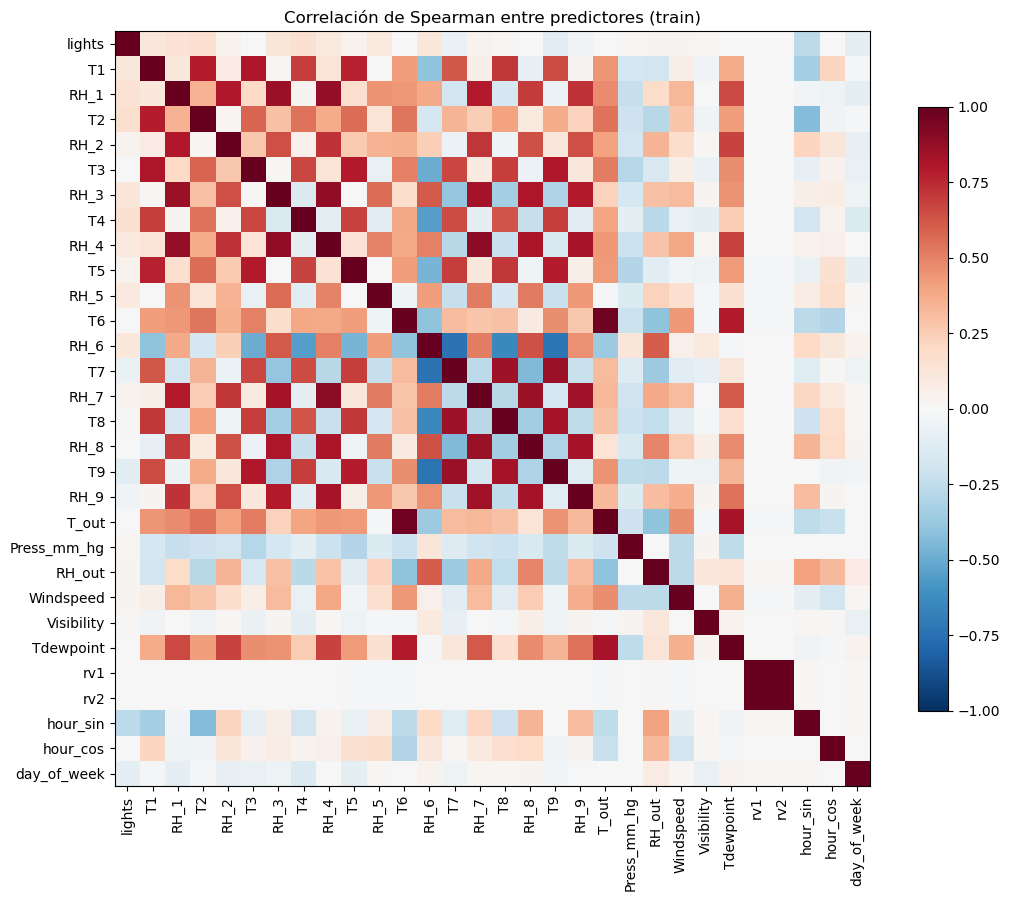

Pares con |rho| >= 0.9: 2


,level_0,level_1,spearman
0,rv1,rv2,1.000
1,T6,T_out,0.976


Pares con |rho| >= 0.9: 2 de 435
Pares con |rho| >= 0.8: 20 de 435
Pares con |rho| >= 0.7: 34 de 435
Entre temperaturas: mediana 0.62, mínimo 0.29, máximo 0.98


In [8]:
corr_train = X_train.corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr_train, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_train))); ax.set_xticklabels(corr_train.columns, rotation=90)
ax.set_yticks(range(len(corr_train))); ax.set_yticklabels(corr_train.columns)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlación de Spearman entre predictores (train)")
plt.tight_layout(); plt.show()

UMBRAL_REDUNDANCIA = 0.90
pares = (corr_train.where(np.triu(np.ones(corr_train.shape, dtype=bool), k=1))
         .stack().rename("spearman").reset_index())
pares = pares[pares["spearman"].abs() >= UMBRAL_REDUNDANCIA].sort_values("spearman", key=abs, ascending=False)
print(f"Pares con |rho| >= {UMBRAL_REDUNDANCIA}: {len(pares)}")
display(pares.reset_index(drop=True))

superior = corr_train.where(np.triu(np.ones(corr_train.shape, dtype=bool), k=1)).stack().abs()
for u in (0.9, 0.8, 0.7):
    print(f"Pares con |rho| >= {u}: {(superior >= u).sum()} de {len(superior)}")
temperaturas = [f"T{i}" for i in range(1, 10)] + ["T_out"]
t_sup = corr_train.loc[temperaturas, temperaturas].where(np.triu(np.ones((10, 10), dtype=bool), k=1)).stack()
print(f"Entre temperaturas: mediana {t_sup.median():.2f}, mínimo {t_sup.min():.2f}, máximo {t_sup.max():.2f}")

Con el umbral estricto de 0,90 solo hay **dos** pares redundantes: `rv1`–`rv2` (idénticas) y
`T6`–`T_out` (ρ ≈ 0,98; tiene sentido, porque el sensor 6 está **afuera** del edificio). Pero la
redundancia es más amplia de lo que muestra ese umbral: hay 20 pares con |ρ| ≥ 0,80, y las temperaturas
tienen una correlación mediana de ≈ 0,6 entre sí porque todas siguen la misma tendencia estacional
(enero → abril). Las humedades interiores forman otro bloque parecido. Para la red, varias versiones de
"qué tan templado está el período" agregan parámetros sin agregar información sobre lo que realmente
mueve el consumo (la ocupación de la casa).

### 4.4 Comportamiento de `rv1` y `rv2`

¿rv1 y rv2 son idénticas? True
     pearson  spearman  info_mutua
rv1   -0.009    -0.008         0.0
rv2   -0.009    -0.008         0.0


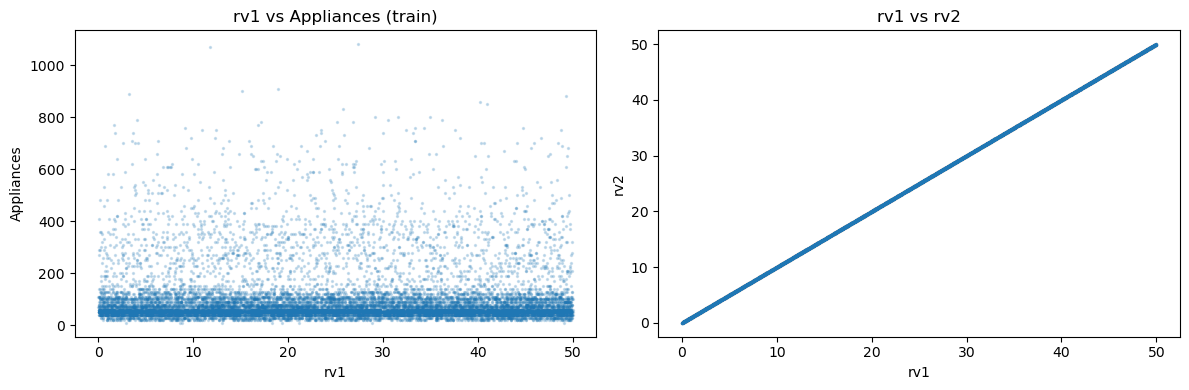

In [9]:
print("¿rv1 y rv2 son idénticas?", np.allclose(X["rv1"], X["rv2"]))
print(asociacion.loc[["rv1", "rv2"], ["pearson", "spearman", "info_mutua"]])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(X_train["rv1"], y_train, s=2, alpha=0.2); ax[0].set(xlabel="rv1", ylabel="Appliances", title="rv1 vs Appliances (train)")
ax[1].scatter(X_train["rv1"], X_train["rv2"], s=2, alpha=0.2); ax[1].set(xlabel="rv1", ylabel="rv2", title="rv1 vs rv2")
plt.tight_layout(); plt.show()

`rv1` y `rv2` son **la misma variable aleatoria duplicada** (correlación 1) y no tienen asociación con
el objetivo (Spearman ≈ 0, información mutua = 0). Son el control negativo del dataset: cualquier método
de selección razonable debería descartarlas, y si alguno las elige es una señal de inestabilidad.

## 5. Rankings de relevancia (solo entrenamiento) — actividad 4

Se aplican cuatro técnicas de las sugeridas por la consigna. Todas usan exclusivamente `X_train`/`y_train`:

1. **Correlación de Spearman** (filtro, ya calculada).
2. **Información mutua** (filtro no lineal, ya calculada).
3. **Regularización L1 (Lasso)** sobre `log1p(Appliances)` — el logaritmo reduce la asimetría para que
   unos pocos picos no dominen el ajuste lineal. El `alpha` se elige con `TimeSeriesSplit` *dentro* de
   train, para no mirar el futuro. El escalado y la penalización se ajustan **dentro de cada fold**
   (un `Pipeline` escalador → Lasso dentro de `GridSearchCV`), así ningún fold de validación interna
   influye en la escala con la que se eligió `alpha`.
4. **Importancia por permutación** de la propia RNA. Para no usar validación ni prueba, se separa una
   **validación interna**: la red se entrena con el primer 80 % de train y se permuta sobre el último 20 %.

In [10]:
def crear_rna(semilla=SEMILLA):
    # Arquitectura, preprocesamiento y semilla del código inicial. Es la ÚNICA definición de modelo
    # del notebook: todos los experimentos solo cambian las columnas que reciben.
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            max_iter=800,
            shuffle=False,
            random_state=semilla,
        )),
    ])

# --- Lasso (L1) ---
# El escalador va dentro del Pipeline que evalúa GridSearchCV: en cada fold de TimeSeriesSplit
# se ajustan escala y penalización solo con la parte de entrenamiento de ese fold.
busqueda_lasso = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("lasso", Lasso(max_iter=20000))]),
    {"lasso__alpha": np.logspace(-4, 0, 40)},
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_mean_squared_error",
).fit(X_train, np.log1p(y_train))
lasso = busqueda_lasso.best_estimator_
coef_lasso = pd.Series(lasso[-1].coef_, index=X.columns)
print(f"Lasso: alpha={busqueda_lasso.best_params_['lasso__alpha']:.4f}, variables con coeficiente != 0: {(coef_lasso != 0).sum()} de {len(coef_lasso)}")

# --- Permutación sobre validación interna (dentro de train) ---
corte = int(0.80 * len(X_train))
rna_interna = crear_rna().fit(X_train.iloc[:corte], y_train.iloc[:corte])
perm = permutation_importance(
    rna_interna, X_train.iloc[corte:], y_train.iloc[corte:],
    scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEMILLA,
)
imp_perm = pd.Series(perm.importances_mean, index=X.columns)

rankings = pd.DataFrame({
    "|spearman|": asociacion["|spearman|"],
    "info_mutua": asociacion["info_mutua"],
    "|coef_lasso|": coef_lasso.abs(),
    "perm_MAE": imp_perm,
})
posiciones = rankings.rank(ascending=False).astype(int).add_prefix("pos_")
display(pd.concat([rankings, posiciones], axis=1).sort_values("pos_|spearman|"))

Lasso: alpha=0.0143, variables con coeficiente != 0: 17 de 30


,|spearman|,info_mutua,|coef_lasso|,perm_MAE,pos_|spearman|,pos_info_mutua,pos_|coef_lasso|,pos_perm_MAE
hour_sin,0.431,0.169,1.769e-01,24.944,1,1,2,1
lights,0.354,0.081,1.425e-01,-0.068,2,17,3,21
T2,0.325,0.108,0.000e+00,0.662,3,8,24,15
hour_cos,0.297,0.109,2.023e-01,11.170,4,7,1,2
T1,0.265,0.088,0.000e+00,2.100,5,13,24,9
T8,0.258,0.115,7.035e-02,-0.827,6,5,5,24
T4,0.240,0.116,8.363e-03,-0.837,7,4,14,25
T3,0.239,0.120,1.134e-01,2.234,8,3,4,8
RH_8,0.235,0.092,0.000e+00,0.876,9,12,24,13
RH_out,0.220,0.038,5.647e-04,1.299,10,25,17,10


Lectura de los rankings:

- **Hora del día** (`hour_sin`, `hour_cos`) y **`lights`** aparecen arriba en casi todos los métodos:
  reflejan la ocupación de la casa, que es lo que realmente mueve el consumo.
- La **información mutua** premia temperaturas (`T9`, `T3`, `T8`) y la **presión** (`Press_mm_hg`).
  Son variables que cambian lento y casi identifican *en qué semana* estamos: dentro de train
  "memorizan" el nivel de consumo de cada período, pero eso no se traslada a semanas futuras.
- La **permutación** sobre la RNA completa es ruidosa: llega a dar importancia positiva a `rv1`/`rv2`,
  que son puro ruido. Es un síntoma de que la red con 30 entradas está sobreajustando.

## 6. Subconjuntos candidatos

Para que los filtros no elijan variables redundantes entre sí, se aplica una **selección voraz con
control de redundancia**: se recorre el ranking de mayor a menor y se agrega una variable solo si su
|Spearman| con todas las ya elegidas es menor a 0,90 (correlación calculada en train).

In [11]:
def seleccion_sin_redundancia(ranking, k, umbral=UMBRAL_REDUNDANCIA, corr=corr_train):
    elegidas = []
    for variable in ranking.sort_values(ascending=False).index:
        if all(abs(corr.loc[variable, otra]) < umbral for otra in elegidas):
            elegidas.append(variable)
        if len(elegidas) == k:
            break
    return elegidas


def evaluar(columnas, X_fit=X_train, y_fit=y_train, X_eval=X_val, y_eval=y_val, semilla=SEMILLA):
    modelo = crear_rna(semilla).fit(X_fit[columnas], y_fit)
    pred = modelo.predict(X_eval[columnas])
    return {
        "n_vars": len(columnas),
        "MAE": mean_absolute_error(y_eval, pred),
        "RMSE": np.sqrt(mean_squared_error(y_eval, pred)),
        "R2": r2_score(y_eval, pred),
    }

### 6.1 ¿Cuántas variables? Barrido de *k* para los dos filtros

Los rankings ya están fijos (calculados en train); en validación solo se elige el tamaño *k*.
Criterio: **menor MAE de validación** (es la métrica más robusta a los picos del objetivo); ante un
empate práctico se prefiere el *k* más chico.

,ranking,k,n_vars,MAE,RMSE,R2,variables
0,spearman,2,2,48.382,89.184,0.065,"hour_sin, lights"
1,spearman,3,3,52.619,90.540,0.036,"hour_sin, lights, T2"
2,spearman,4,4,47.402,86.923,0.112,"hour_sin, lights, T2, hour_cos"
3,spearman,5,5,49.661,89.481,0.059,"hour_sin, lights, T2, hour_cos, T1"
4,spearman,6,6,49.694,90.299,0.042,"hour_sin, lights, T2, hour_cos, T1, T8"
5,spearman,8,8,50.858,90.711,0.033,"hour_sin, lights, T2, hour_cos, T1, T8, T4, T3"
6,spearman,10,10,59.584,97.233,-0.111,"hour_sin, lights, T2, hour_cos, T1, T8, T4, T3..."
7,spearman,12,12,56.703,97.507,-0.117,"hour_sin, lights, T2, hour_cos, T1, T8, T4, T3..."
8,info_mutua,2,2,53.120,89.792,0.052,"hour_sin, T9"
9,info_mutua,3,3,52.181,89.285,0.063,"hour_sin, T9, T3"


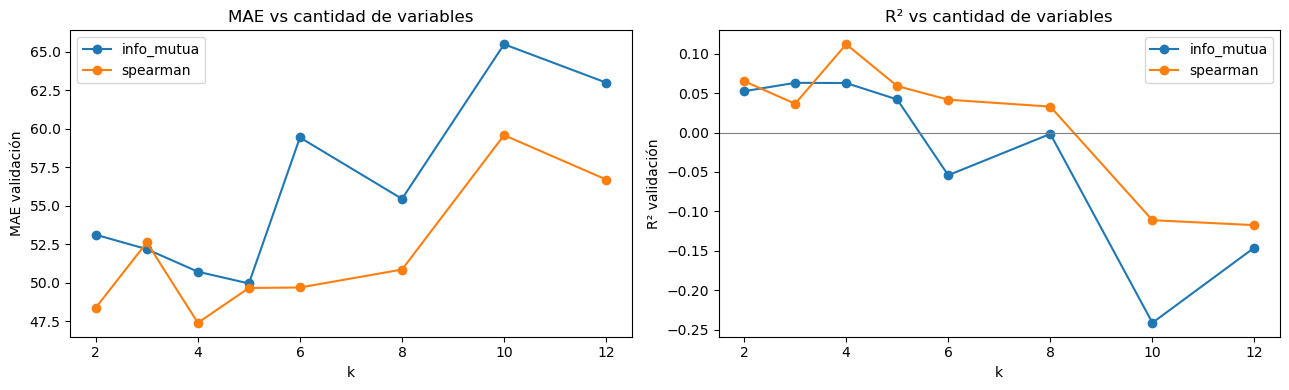

k elegido por ranking: {'info_mutua': 5, 'spearman': 4}


In [12]:
barrido = []
for nombre, ranking in [("spearman", asociacion["|spearman|"]), ("info_mutua", asociacion["info_mutua"])]:
    for k in [2, 3, 4, 5, 6, 8, 10, 12]:
        cols = seleccion_sin_redundancia(ranking, k)
        barrido.append({"ranking": nombre, "k": k, **evaluar(cols), "variables": ", ".join(cols)})
barrido = pd.DataFrame(barrido)
display(barrido)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for nombre, g in barrido.groupby("ranking"):
    ax[0].plot(g["k"], g["MAE"], marker="o", label=nombre)
    ax[1].plot(g["k"], g["R2"], marker="o", label=nombre)
ax[0].set(xlabel="k", ylabel="MAE validación", title="MAE vs cantidad de variables")
ax[1].set(xlabel="k", ylabel="R² validación", title="R² vs cantidad de variables")
ax[1].axhline(0, color="gray", lw=0.8)
for a in ax: a.legend()
plt.tight_layout(); plt.show()

mejor_k = {nombre: int(g.loc[g["MAE"].idxmin(), "k"]) for nombre, g in barrido.groupby("ranking")}
print("k elegido por ranking:", mejor_k)

### 6.2 Candidatos definitivos

In [13]:
candidatos = {
    "todas (30)": list(X.columns),
    "todas sin rv1/rv2": [c for c in X.columns if c not in ("rv1", "rv2")],
    f"S1 Spearman+redund. (k={mejor_k['spearman']})": seleccion_sin_redundancia(asociacion["|spearman|"], mejor_k["spearman"]),
    f"S2 Info mutua+redund. (k={mejor_k['info_mutua']})": seleccion_sin_redundancia(asociacion["info_mutua"], mejor_k["info_mutua"]),
    "S3 Lasso L1 (coef != 0)": list(coef_lasso[coef_lasso != 0].index),
    "S4 Permutación RNA (> 0)": list(imp_perm[imp_perm > 0].sort_values(ascending=False).index),
}
for nombre, cols in candidatos.items():
    print(f"{nombre:32s} -> {cols}")

todas (30)                       -> ['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'hour_sin', 'hour_cos', 'day_of_week']
todas sin rv1/rv2                -> ['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'hour_sin', 'hour_cos', 'day_of_week']
S1 Spearman+redund. (k=4)        -> ['hour_sin', 'lights', 'T2', 'hour_cos']
S2 Info mutua+redund. (k=5)      -> ['hour_sin', 'T9', 'T3', 'T4', 'T8']
S3 Lasso L1 (coef != 0)          -> ['lights', 'RH_1', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_5', 'T6', 'RH_7', 'T8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'hour_sin', 'hour_cos']
S4 Permutación RNA (> 0)         -> ['hour_sin', 'hour_cos', 'T6', 'T5', 'RH_2', 

## 7. Comparación con la misma arquitectura (actividad 5)

Misma función `crear_rna()`, misma partición, misma semilla, mismo escalado. Solo cambian las columnas.
Se agregan dos referencias ingenuas (predecir siempre la media / mediana de train) para dimensionar
qué tan difícil es el problema.

In [14]:
resultados_val = pd.DataFrame({nombre: evaluar(cols) for nombre, cols in candidatos.items()}).T
for nombre, valor in [("referencia: media de train", y_train.mean()), ("referencia: mediana de train", y_train.median())]:
    pred = np.full(len(y_val), valor)
    resultados_val.loc[nombre] = [0, mean_absolute_error(y_val, pred), np.sqrt(mean_squared_error(y_val, pred)), r2_score(y_val, pred)]
resultados_val["n_vars"] = resultados_val["n_vars"].astype(int)
display(resultados_val.sort_values("MAE"))

,n_vars,MAE,RMSE,R2
referencia: mediana de train,0,42.605,98.108,-0.131
S1 Spearman+redund. (k=4),4,47.402,86.923,0.112
S2 Info mutua+redund. (k=5),5,49.956,90.287,0.042
referencia: media de train,0,53.968,92.394,-0.003
todas (30),30,60.759,104.607,-0.286
todas sin rv1/rv2,28,67.174,116.888,-0.606
S4 Permutación RNA (> 0),19,67.491,114.936,-0.553
S3 Lasso L1 (coef != 0),17,67.676,109.122,-0.400


## 8. Estabilidad de la selección

Una selección que cambia mucho con pequeñas variaciones de los datos no es confiable. Se miran dos cosas:

1. **Estabilidad de las variables elegidas:** se repite el procedimiento S1 (ranking Spearman +
   control de redundancia, con el *k* elegido) en **4 bloques temporales consecutivos de train** y se
   cuenta cuántas veces sale cada variable.
2. **Estabilidad del resultado frente a la inicialización:** se repite la comparación "todas vs. S1" con
   5 semillas. (La comparación principal usa siempre la semilla 42; esto es solo un control adicional.)

In [15]:
k_s1 = mejor_k["spearman"]
frecuencia = pd.Series(0, index=X.columns)
for i, bloque in enumerate(np.array_split(np.arange(len(X_train)), 4)):
    Xb, yb = X_train.iloc[bloque], y_train.iloc[bloque]
    rank_b = Xb.corrwith(yb, method="spearman").abs()
    elegidas_b = seleccion_sin_redundancia(rank_b, k_s1, corr=Xb.corr(method="spearman"))
    print(f"Bloque {i + 1} ({fechas.iloc[bloque[0]].date()} a {fechas.iloc[bloque[-1]].date()}): {elegidas_b}")
    frecuencia[elegidas_b] += 1
print("\nFrecuencia de selección (sobre 4 bloques):")
print(frecuencia[frecuencia > 0].sort_values(ascending=False).to_string())

Bloque 1 (2016-01-11 a 2016-02-04): ['lights', 'T2', 'hour_sin', 'T4']
Bloque 2 (2016-02-04 a 2016-02-28): ['hour_sin', 'hour_cos', 'lights', 'T8']
Bloque 3 (2016-02-28 a 2016-03-23): ['hour_sin', 'RH_8', 'T2', 'RH_9']
Bloque 4 (2016-03-23 a 2016-04-16): ['hour_sin', 'T6', 'T2', 'hour_cos']

Frecuencia de selección (sobre 4 bloques):
hour_sin    4
T2          3
lights      2
hour_cos    2
T4          1
T6          1
T8          1
RH_8        1
RH_9        1


In [16]:
S1 = candidatos[f"S1 Spearman+redund. (k={k_s1})"]
filas = []
for semilla in [0, 1, 2, 3, 42]:
    filas.append({"semilla": semilla, "conjunto": "todas (30)", **evaluar(list(X.columns), semilla=semilla)})
    filas.append({"semilla": semilla, "conjunto": "S1", **evaluar(S1, semilla=semilla)})
por_semilla = pd.DataFrame(filas)
display(por_semilla.pivot(index="semilla", columns="conjunto", values=["MAE", "R2"]))
display(por_semilla.groupby("conjunto")[["MAE", "RMSE", "R2"]].agg(["mean", "std"]))

MAE                R2           
conjunto      S1 todas (30)     S1 todas (30)
semilla                                      
0         48.155     60.737  0.056     -0.239
1         48.253     64.180  0.082     -0.350
2         47.626     66.262  0.097     -0.415
3         49.184     65.781  0.037     -0.442
42        47.402     60.759  0.112     -0.286

MAE            RMSE            R2       
              mean    std     mean    std   mean    std
conjunto                                               
S1          48.124  0.691   88.621  1.449  0.077  0.030
todas (30)  63.544  2.666  106.986  3.398 -0.346  0.085

## 9. Selección final y justificación (actividad 7)

In [17]:
seleccion_final = S1
print("Variables finales:", seleccion_final)
display(rankings.loc[seleccion_final])

Variables finales: ['hour_sin', 'lights', 'T2', 'hour_cos']


,|spearman|,info_mutua,|coef_lasso|,perm_MAE
hour_sin,0.431,0.169,0.177,24.944
lights,0.354,0.081,0.142,-0.068
T2,0.325,0.108,0.000,0.662
hour_cos,0.297,0.109,0.202,11.170


**Variables finales (4):** `hour_sin`, `hour_cos`, `lights`, `T2`.

| Criterio | Evidencia (todo medido antes de tocar la prueba) |
|---|---|
| **Relevancia** | Son las 4 de mayor \|Spearman\| con el objetivo en train. `hour_sin`/`hour_cos` además encabezan la información mutua, el Lasso y la permutación: los cuatro métodos coinciden en que la hora es lo más informativo. |
| **Interpretabilidad** | La hora del día y las luces encendidas son indicadores directos de **ocupación** (gente en la casa usando electrodomésticos). `T2` (living) es la temperatura más asociada al consumo: sube cuando la casa está habitada y calefaccionada. |
| **Redundancia** | Ningún par del subconjunto supera \|ρ\| = 0,90 (control voraz). Se elige `T2` como única representante del bloque de temperaturas en lugar de 10 versiones correlacionadas. `hour_sin` y `hour_cos` no son redundantes: juntas codifican la hora sobre un círculo. |
| **Desempeño en validación** | MAE 47,4 y R² 0,112 contra MAE 60,8 y R² −0,286 de las 30 variables (−22 % de MAE). Es el mejor de los seis candidatos y el mejor *k* del barrido. |
| **Estabilidad** | Con 5 semillas: MAE 48,1 ± 0,7 (todas: 63,5 ± 2,7) y R² positivo en las 5 (todas: negativo en las 5). En los 4 bloques temporales de train, `hour_sin` sale siempre y `T2` en 3 de 4; `lights` y `hour_cos`, en 2 de 4. Lo que varía entre bloques es qué temperatura o humedad acompaña, otro indicio de que esas variables son intercambiables. |
| **Cantidad** | 4 de 30 variables. |

**¿Por qué no los otros candidatos?** S2 (información mutua) prioriza temperaturas lentas (`T9`, `T3`,
`T4`, `T8`) que dentro de train identifican el período del año más que el consumo; S3 (Lasso, 17
variables) y S4 (permutación, 19) conservan demasiadas variables y quedan peor incluso que la red
completa. S4 además incluye `rv1` y `rv2`, que son ruido puro: la permutación sobre una red que
sobreajusta no es confiable.

**Ojo con la referencia "mediana".** Predecir siempre 60 Wh tiene menor MAE que la red (42,6 contra
47,4) porque el objetivo es muy asimétrico y la mayor parte del tiempo el consumo está cerca de la
mediana. Pero esa referencia tiene R² negativo y RMSE mayor (98 contra 87): no anticipa ningún pico. La
red con 4 variables es la única configuración con R² positivo; aun así, el problema es difícil y el R²
es bajo.

## 10. Evaluación en prueba (una sola vez)

Configuración congelada: arquitectura `crear_rna()`, semilla 42, entrenamiento con `X_train`, y dos
conjuntos de variables (todas vs. selección final). Esta es la **única** celda que usa `X_test`.

MAE     RMSE     R2
conjunto            partición                          
todas (30)          validación   60.759  104.607 -0.286
                    prueba      171.311  226.167 -5.194
selección final (4) validación   47.402   86.923  0.112
                    prueba       50.474   89.911  0.021

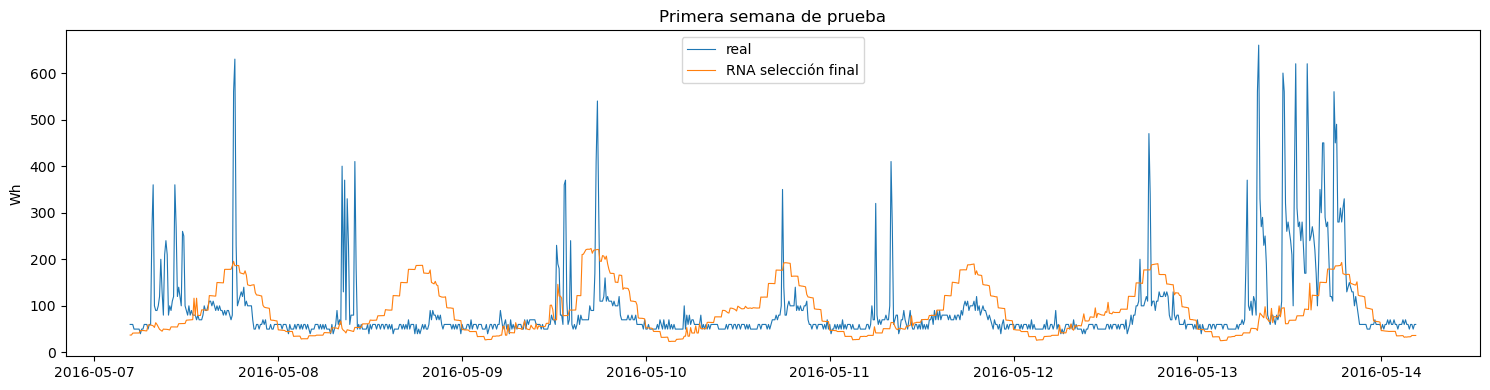

In [18]:
filas = []
for nombre, cols in [("todas (30)", list(X.columns)), (f"selección final ({len(seleccion_final)})", seleccion_final)]:
    modelo = crear_rna().fit(X_train[cols], y_train)
    for particion, Xe, ye in [("validación", X_val, y_val), ("prueba", X_test, y_test)]:
        pred = modelo.predict(Xe[cols])
        filas.append({"conjunto": nombre, "partición": particion,
                      "MAE": mean_absolute_error(ye, pred),
                      "RMSE": np.sqrt(mean_squared_error(ye, pred)),
                      "R2": r2_score(ye, pred)})
    if cols is seleccion_final:
        pred_test_final = pred
final = pd.DataFrame(filas).set_index(["conjunto", "partición"])
display(final)

fig, ax = plt.subplots(figsize=(15, 4))
ventana = slice(0, 1008)  # una semana de prueba (144 registros por día)
ax.plot(fechas.iloc[fin_val:].iloc[ventana], y_test.iloc[ventana], lw=0.8, label="real")
ax.plot(fechas.iloc[fin_val:].iloc[ventana], pred_test_final[ventana], lw=0.8, label="RNA selección final")
ax.set(title="Primera semana de prueba", ylabel="Wh"); ax.legend()
plt.tight_layout(); plt.show()

### 10.1 Diagnóstico posterior: ¿por qué se dispara el error de la red completa en prueba?

Esta celda **no** se usa para elegir nada (la selección ya está congelada). Solo sirve para explicar
el resultado: se mide qué fracción de los registros de validación y de prueba tiene alguna variable
**fuera del rango observado en train**.

In [19]:
minimo, maximo = X_train.min(), X_train.max()
fuera = pd.DataFrame({
    nombre: ((Xe < minimo) | (Xe > maximo)).mean()
    for nombre, Xe in [("validación", X_val), ("prueba", X_test)]
})
print("Filas con al menos una variable fuera del rango de train:")
for nombre, Xe in [("validación", X_val), ("prueba", X_test)]:
    print(f"  {nombre}: {((Xe < minimo) | (Xe > maximo)).any(axis=1).mean():.0%}")
sf = seleccion_final
print("Solo las variables de la selección final, filas fuera de rango en prueba:",
      f"{((X_test[sf] < minimo[sf]) | (X_test[sf] > maximo[sf])).any(axis=1).mean():.0%}")
display(fuera[fuera.max(axis=1) > 0].sort_values("prueba", ascending=False).style.format("{:.0%}"))
print("Media de T_out — train: %.1f °C · prueba: %.1f °C" % (X_train["T_out"].mean(), X_test["T_out"].mean()))

Filas con al menos una variable fuera del rango de train:
  validación: 18%
  prueba: 80%
Solo las variables de la selección final, filas fuera de rango en prueba: 26%


,validación,prueba
T4,3%,65%
T1,2%,55%
T7,1%,54%
T5,0%,49%
Tdewpoint,0%,32%
T8,0%,29%
T2,6%,26%
T6,3%,23%
T9,0%,18%
T_out,2%,15%


Media de T_out — train: 5.7 °C · prueba: 14.5 °C


## 11. Discusión: redundancia, estabilidad y posibles fugas

**Redundancia.** El dataset tiene redundancia exacta (`rv1` = `rv2`), casi exacta (`T6` ≈ `T_out`) y
una redundancia "blanda" pero extendida entre temperaturas y humedades, que comparten la tendencia
estacional. La selección final se queda con una sola temperatura y ninguna humedad.

**Estabilidad.** La selección es estable en lo importante (la hora sale en los 4 bloques temporales y
en todos los métodos) y su desempeño es estable frente a la semilla (desvío del MAE de 0,7, contra 2,7
de la red completa). La red con 30 entradas es inestable: cambia bastante con la semilla e incluso
empeora al quitarle solo `rv1`/`rv2` (MAE 67 contra 61). Eso muestra que su desempeño depende más del
azar de la optimización que de la información disponible.

**Fugas y riesgos considerados:**

- **Fuga temporal en la partición:** corte cronológico sin mezclar, y `shuffle=False` también en el
  entrenamiento del MLP, como en el código inicial.
- **Fuga en la selección:** todos los rankings, el `alpha` del Lasso (con `TimeSeriesSplit`, escalando dentro de cada fold) y la
  permutación (validación *interna* dentro de train) usan solo entrenamiento. La validación se usó solo
  para elegir *k* y comparar candidatos; la prueba, una vez.
- **Fuga en el escalado:** el `StandardScaler` está dentro del `Pipeline` y se ajusta con train.
- **La fecha como identificador:** no se usa `date` ni ningún contador de tiempo. Las variables que
  cambian lento (presión, temperaturas) pueden funcionar como un "reloj" del período y permitir que la red
  memorice el nivel de consumo de cada semana: es justamente lo que premia el ranking de información
  mutua y lo que la selección final evita.
- **No se usaron rezagos del objetivo** (`Appliances` de los 10 minutos anteriores). Mejorarían mucho
  las métricas, pero cambian el problema (pronóstico a un paso con el consumo actual conocido) y no forman
  parte de la consigna.
- **Extrapolación (cambio de distribución):** mayo es más cálido que enero–abril. En prueba, el 80 % de
  los registros tiene alguna variable fuera del rango de train. La red con 30 entradas extrapola en muchas
  direcciones a la vez y su error se dispara; la de 4 variables depende sobre todo de la hora y de
  `lights`, cuya distribución no cambia con la estación.

## 12. Conclusión

Con la misma RNA, partición y semilla, pasar de 30 a 4 variables (`hour_sin`, `hour_cos`, `lights`, `T2`) mejora la validación (MAE 60,8 → 47,4; R² −0,29 → 0,11) y evita el colapso en prueba (MAE 171,3 → 50,5; R² −5,19 → 0,02), donde la red completa extrapola mal ante un mes más cálido que los de entrenamiento. La selección vuelve al modelo más simple y robusto, aunque el R² sigue siendo bajo: el consumo depende sobre todo de la ocupación de la casa (hora y luces), y estas variables solo lo explican en parte.